# Entanglement: the Four Bell States

**H** on q0 creates a superposition, and **CNOT** (q0 → q1) entangles the two
qubits. X gates applied *before* H + CNOT choose which of the four Bell states
is produced. Each cell builds and draws one of them (q2 is not used).

| Cell | X gates before H + CNOT | Bell state |
|---|---|---|
| 1 | none | \|Φ+⟩ = (\|00⟩ + \|11⟩)/√2 |
| 2 | X on q0 | \|Φ−⟩ = (\|00⟩ − \|11⟩)/√2 |
| 3 | X on q1 | \|Ψ+⟩ = (\|01⟩ + \|10⟩)/√2 |
| 4 | X on q0 and q1 | \|Ψ−⟩ = (\|01⟩ − \|10⟩)/√2 |

Measuring a Φ state always gives **equal** bits; a Ψ state always gives **opposite** bits.

### 1. |Φ+⟩ = (|00⟩ + |11⟩)/√2
The U(0, 0, 0) gates are identity gates, so the input stays |00⟩.

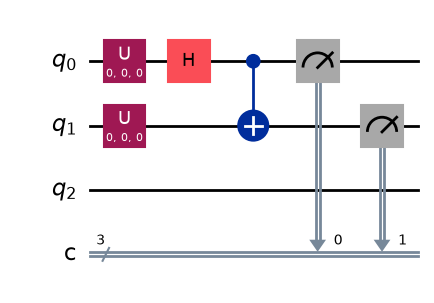

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import Aer

backend = Aer.get_backend("qasm_simulator")  # local QASM simulator
shots = 1024

qc = QuantumCircuit()
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc.add_register(q)
qc.add_register(c)

qc.u(0, 0, 0, q[0])
qc.u(0, 0, 0, q[1])
qc.h(q[0])
qc.cx(q[0], q[1])
qc.measure(q[0], c[0])
qc.measure(q[1], c[1])

qc.draw(output='mpl')   # <-- last line, no plt.show() — notebook auto-renders this

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_4_1_PhiPlus.png", dpi=300, bbox_inches="tight")

### 2. |Φ−⟩ = (|00⟩ − |11⟩)/√2

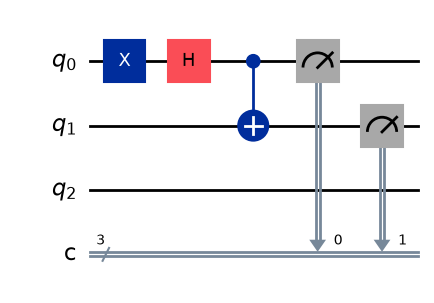

In [3]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import Aer

backend = Aer.get_backend("qasm_simulator")
shots = 1024

qc = QuantumCircuit()
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc.add_register(q)
qc.add_register(c)

# --- Prep step: flip q0 to |1> so H+CX lands on the "-" phase state ---
qc.x(q[0])            # X gate: |0> -> |1>, sets up starting state |10>

# --- Entangling step ---
qc.h(q[0])            # superposition on q0
qc.cx(q[0], q[1])      # CNOT -> entangles into Bell state |Phi->

# --- Measurement ---
qc.measure(q[0], c[0])
qc.measure(q[1], c[1])

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

In [4]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_4_2_PhiMinus.png", dpi=300, bbox_inches="tight")

### 3. |Ψ+⟩ = (|01⟩ + |10⟩)/√2

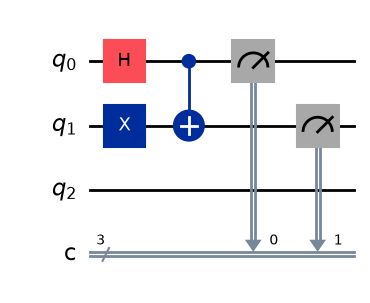

In [5]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import Aer

backend = Aer.get_backend("qasm_simulator")
shots = 1024

qc = QuantumCircuit()
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc.add_register(q)
qc.add_register(c)

# --- Prep step: flip q1 to |1> so H+CX lands on the anti-correlated state ---
qc.x(q[1])            # X gate: |0> -> |1>, sets up starting state |01>

# --- Entangling step ---
qc.h(q[0])            # superposition on q0
qc.cx(q[0], q[1])      # CNOT -> entangles into Bell state |Psi+>

# --- Measurement ---
qc.measure(q[0], c[0])
qc.measure(q[1], c[1])

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

In [6]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_4_3_PsiPlus.png", dpi=300, bbox_inches="tight")

### 4. |Ψ−⟩ = (|01⟩ − |10⟩)/√2

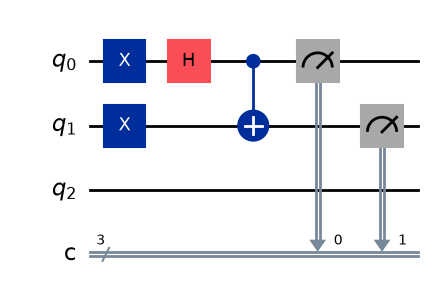

In [7]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import Aer

backend = Aer.get_backend("qasm_simulator")
shots = 1024

qc = QuantumCircuit()
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc.add_register(q)
qc.add_register(c)

# --- Prep step: flip BOTH qubits to |1> so H+CX lands on the "-" phase, anti-correlated state ---
qc.x(q[0])   # X gate: |0> -> |1>
qc.x(q[1])   # X gate: |0> -> |1>, together set up starting state |11>

# --- Entangling step ---
qc.h(q[0])            # superposition on q0
qc.cx(q[0], q[1])      # CNOT -> entangles into Bell state |Psi->

# --- Measurement ---
qc.measure(q[0], c[0])
qc.measure(q[1], c[1])

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

In [8]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_4_4_PsiMinus.png", dpi=300, bbox_inches="tight")